**Live demo:**:  https://ml-titanic-survival-prediction-by-wajahat.streamlit.app/

# Titanic Passenger Survival Prediction System
AIC354 Assignment 2 · Task 1 · full Titanic dataset (891 passengers)

**Inputs:** `PClass`, `Gender`, `Sibling`, `Embarked` · **Target:** `Survived` (Yes/No)

In [ ]:
import pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Phase 1: Data collection

In [2]:
df = pd.read_csv('titanic.csv')   # full Titanic dataset, 891 passengers
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Data understanding

survived    0
pclass      0
sex         0
sibsp       0
embarked    2
dtype: int64
survived
0    549
1    342
Name: count, dtype: int64


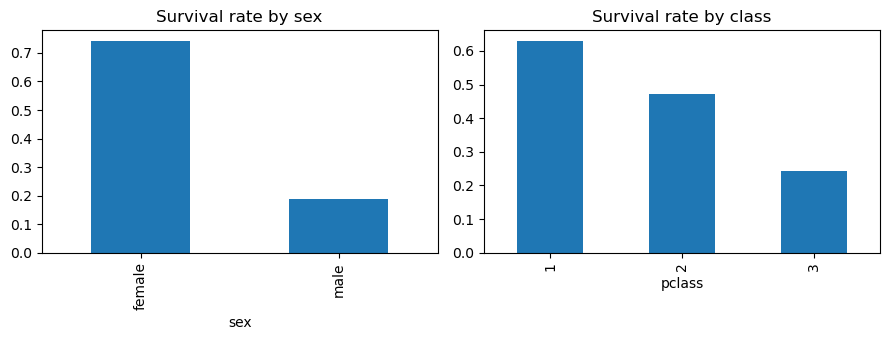

In [3]:
print(df[['survived','pclass','sex','sibsp','embarked']].isna().sum())   # embarked has missing values
print(df['survived'].value_counts())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
df.groupby('sex')['survived'].mean().plot.bar(ax=ax[0], title='Survival rate by sex')
df.groupby('pclass')['survived'].mean().plot.bar(ax=ax[1], title='Survival rate by class')
plt.tight_layout(); plt.show()

## Data preprocessing
Keep 4 columns, drop the 2 rows with missing `embarked`, and turn the numeric codes into readable text categories.

In [4]:
data = df[['pclass','sex','sibsp','embarked','survived']].dropna().copy()
data['PClass'] = data['pclass'].map({1:'First', 2:'Second', 3:'Third'})
data['Gender'] = data['sex'].str.capitalize()
data['Sibling'] = data['sibsp'].clip(upper=3).map({0:'Zero', 1:'One', 2:'Two', 3:'Three or more'})
data['Embarked'] = data['embarked'].map({'S':'Southampton', 'C':'Cherbourg', 'Q':'Queenstown'})
data['Survived'] = data['survived']   # already 0/1
FEATURES = ['PClass', 'Gender', 'Sibling', 'Embarked']
X, y = data[FEATURES], data['Survived']
print(data.shape); data[FEATURES + ['Survived']].head()

(889, 10)


,PClass,Gender,Sibling,Embarked,Survived
0,Third,Male,One,Southampton,0
1,First,Female,One,Cherbourg,1
2,Third,Female,Zero,Southampton,1
3,First,Female,One,Southampton,1
4,Third,Male,Zero,Southampton,0


## Label encoding
Every text feature is converted to numbers with a fixed category order, inside the pipeline so the saved model accepts raw text.

In [5]:
CATS = [['First','Second','Third'], ['Male','Female'], ['Zero','One','Two','Three or more'], ['Southampton','Cherbourg','Queenstown']]
encode = ColumnTransformer([('label', OrdinalEncoder(categories=CATS), FEATURES)])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
print(encode.fit_transform(X_train)[:5])

[[0. 0. 1. 1.]
 [2. 0. 0. 1.]
 [0. 0. 0. 0.]
 [1. 1. 1. 1.]
 [2. 1. 0. 0.]]


## Phase 2 and 3: Model selection and training

In [6]:
models = {'SVC': SVC(gamma='auto', probability=True, random_state=0),
          'Logistic Regression': LogisticRegression(),
          'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=0)}
fitted = {}
for name, m in models.items():
    fitted[name] = Pipeline([('encode', encode), ('model', m)]).fit(X_train, y_train)
    print(name, 'accuracy:', round(accuracy_score(y_test, fitted[name].predict(X_test)), 3))

SVC accuracy: 0.837
Logistic Regression accuracy: 0.831
Decision Tree accuracy: 0.854


## Phase 4: Evaluation
The assignment system uses the SVC, so it is evaluated in detail.

              precision    recall  f1-score   support

Not survived       0.86      0.87      0.87       110
    Survived       0.79      0.78      0.79        68

    accuracy                           0.84       178
   macro avg       0.83      0.83      0.83       178
weighted avg       0.84      0.84      0.84       178



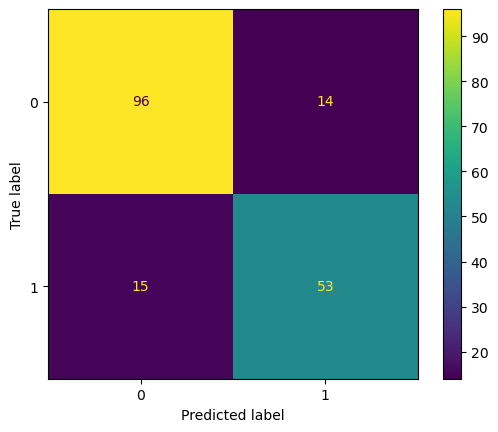

In [7]:
model = fitted['SVC']
pred = model.predict(X_test)
print(classification_report(y_test, pred, target_names=['Not survived', 'Survived']))
ConfusionMatrixDisplay.from_predictions(y_test, pred); plt.show()

## Save the model and test a prediction

In [8]:
joblib.dump(model, 'titanic_model.pkl')
new = pd.DataFrame([{'PClass': 'First', 'Gender': 'Female', 'Sibling': 'Zero', 'Embarked': 'Cherbourg'}])
loaded = joblib.load('titanic_model.pkl')
print('Prediction:', 'SURVIVED' if loaded.predict(new)[0] == 1 else 'NOT SURVIVED')

Prediction: SURVIVED
